# Model evaluation and interpretation

We evaluate the models fitted in Notebook 03 and ask how much friendship contact adds beyond the contextual measures. The held-out sample has been inspected during model development, so we interpret the evaluation as exploratory.

## 1 Import libraries and load the data and models

We load the same test rows used in Notebook 03.

In [1]:
from pathlib import Path
import hashlib
import sklearn
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
processed = root / "data/processed"
tables = root / "results/tables/modelling"
figures = root / "results/figures/presentation2"
sample_path = processed / "eu_loneliness_analysis_sample.csv"
sample = pd.read_csv(sample_path)
# We load the models produced locally by Notebook 03.
saved = joblib.load(processed / "presentation2_models.joblib")
if hashlib.sha256(sample_path.read_bytes()).hexdigest() != saved["sample_sha256"]:
    raise ValueError("The sample has changed. Rerun Notebook 03 before evaluation.")
if sklearn.__version__ != saved["sklearn_version"]:
    raise ValueError("Use the same scikit-learn version as Notebook 03.")
assert not set(saved["train"]).intersection(saved["test"])
test = sample.loc[saved["test"]]
observed = test["ucla_total"]
selected = saved["selected"]
from IPython.display import display

## 2 Generate predictions and calculate test errors

We compare the final model with the baselines to see how much it improves on a single prediction for everyone. We report MAE in loneliness points and include RMSE because it gives larger errors more weight.

In [2]:
predictions = pd.DataFrame({name: model.predict(test[saved["full"]])
                            for name, model in saved["models"].items()}, index=test.index)
contact_predictions = pd.DataFrame({
    name: model.predict(test[saved["predictor_sets"][name]])
    for name, model in saved["ridge_models"].items()
}, index=test.index)

def test_metrics(predicted):
    return pd.DataFrame({
        "MAE": predicted.apply(lambda p: mean_absolute_error(observed, p)),
        "RMSE": predicted.apply(lambda p: root_mean_squared_error(observed, p)),
        "R2": predicted.apply(lambda p: r2_score(observed, p)),
        "outside_score_range": ((predicted < 3) | (predicted > 9)).sum(),
    })

for filename, predicted in [("final_test_metrics", predictions),
                            ("predictor_sets_test", contact_predictions)]:
    metrics = test_metrics(predicted)
    metrics.to_csv(tables / (filename + ".csv"))
    display(metrics.round(3))

,MAE,RMSE,R2,outside_score_range
Ridge,1.223,1.530,0.317,89
Median baseline,1.556,1.851,-0.000,0
Mean baseline,1.557,1.851,-0.000,0


,MAE,RMSE,R2,outside_score_range
Face-to-face only,1.537,1.815,0.038,0
Remote only,1.552,1.833,0.020,0
Both contact types,1.534,1.814,0.040,0
Context only,1.227,1.534,0.313,86
Context + face-to-face,1.223,1.530,0.317,88
Context + remote,1.226,1.532,0.315,84
Context + both,1.223,1.530,0.317,89


## 3 Compare results with and without survey weights

The EU27 weight adjusts for differences in sample composition and country population size. We compare weighted and unweighted correlations and test errors using the same respondents. Model fitting and selection are unweighted. These weighted point estimates do not account for every source of survey uncertainty.

,unweighted_rho,unweighted_p,weighted_rho
contact,,,
friends_meet_face,-0.173,0.0,-0.142
friends_meet_tele,-0.139,0.0,-0.102


,unweighted_MAE,weighted_MAE
Ridge,1.223,1.230
Median baseline,1.556,1.567
Mean baseline,1.557,1.567
Face-to-face only,1.537,1.570
Remote only,1.552,1.575
Both contact types,1.534,1.566
Context only,1.227,1.232
Context + face-to-face,1.223,1.230
Context + remote,1.226,1.232
Context + both,1.223,1.230


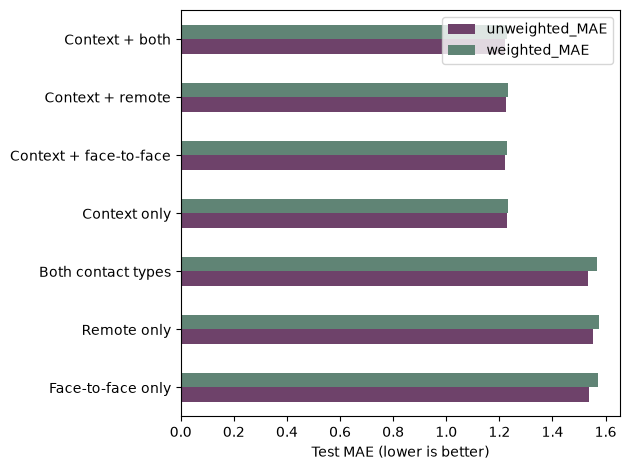

In [3]:
weights = sample["w_eu27"]
if not np.isfinite(weights).all() or not weights.gt(0).all():
    raise ValueError("The analysis sample must have a positive EU27 weight for each respondent.")

def weighted_ranks(values, weights):
    # Tied values share the midpoint of their combined survey weight.
    totals = weights.groupby(values, sort=True).sum()
    return values.map(totals.cumsum() - totals / 2)

def weighted_correlation(x, y, weights):
    x = x - np.average(x, weights=weights)
    y = y - np.average(y, weights=weights)
    return np.average(x * y, weights=weights) / np.sqrt(
        np.average(x ** 2, weights=weights) * np.average(y ** 2, weights=weights)
    )

rho = []
for column in ["friends_meet_face", "friends_meet_tele"]:
    contact, loneliness = sample[column], sample["ucla_total"]
    ordinary = spearmanr(contact, loneliness)
    weighted = weighted_correlation(weighted_ranks(contact, weights),
                                    weighted_ranks(loneliness, weights), weights)
    rho.append({"contact": column, "unweighted_rho": ordinary.statistic,
                "unweighted_p": ordinary.pvalue, "weighted_rho": weighted})
correlations = pd.DataFrame(rho).set_index("contact")
correlations.to_csv(tables / "spearman_weight_comparison.csv")
display(correlations.round(3))

all_predictions = pd.concat([predictions, contact_predictions], axis=1)
errors = all_predictions.sub(observed, axis=0).abs()
weighted_mae = pd.DataFrame({
    "unweighted_MAE": errors.mean(),
    "weighted_MAE": errors.apply(lambda e: np.average(e, weights=weights.loc[e.index])),
})
weighted_mae.to_csv(tables / "test_mae_weight_comparison.csv")
display(weighted_mae.round(3))
ax = weighted_mae.loc[contact_predictions.columns].plot.barh(color=["#6e426a", "#608475"])
ax.set(xlabel="Test MAE (lower is better)", ylabel="")
plt.tight_layout()
plt.savefig(figures / "03_predictor_sets_test.png", dpi=180)
plt.show()

## 4 Compare test errors on the same respondents

We resample the same test respondents for both models in each pair. Positive differences indicate lower MAE for the second model. The intervals describe uncertainty for these fitted predictions, conditional on this split, rather than the full model-development process. They are unweighted.

In [4]:
rng = np.random.default_rng(42)
pairs = [("Remote only", "Face-to-face only"), ("Context only", "Context + both"),
         ("Context + remote", "Context + both"), ("Context + face-to-face", "Context + both")]
if selected != "Median baseline":
    pairs.append(("Median baseline", selected))
differences = pd.DataFrame({f"{a} → {b}": errors[a] - errors[b] for a, b in pairs})
draws = np.array([differences.to_numpy()[rng.integers(len(test), size=len(test))].mean(axis=0)
                  for _ in range(2000)])
intervals = pd.DataFrame({"MAE improvement": differences.mean(),
                          "95% lower": np.quantile(draws, .025, axis=0),
                          "95% upper": np.quantile(draws, .975, axis=0)})
intervals.to_csv(tables / "paired_test_mae_comparisons.csv")
display(intervals.round(3))

,MAE improvement,95% lower,95% upper
Remote only → Face-to-face only,0.016,0.007,0.024
Context only → Context + both,0.005,0.002,0.008
Context + remote → Context + both,0.003,0.001,0.005
Context + face-to-face → Context + both,0.000,-0.001,0.001
Median baseline → Ridge,0.334,0.309,0.358


## 5 Check predictions across the score range

Average error can hide a pattern where the model predicts too high for people with low scores and too low for people with high scores. We compare the predictions against each observed score and plot the residuals to check for this.

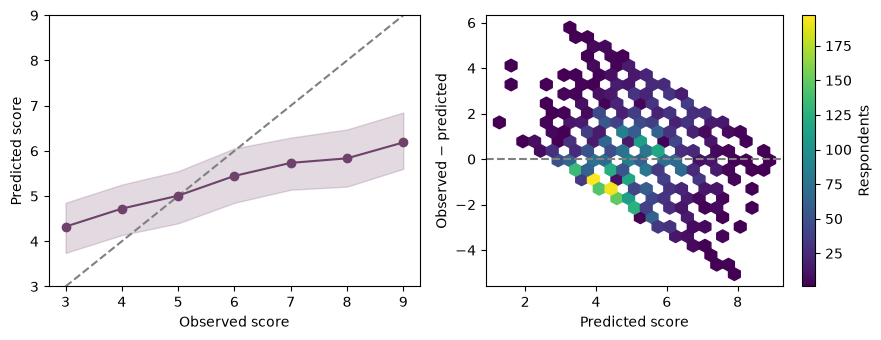

In [5]:
diagnostics = pd.DataFrame({"observed": observed, "predicted": predictions[selected]})
diagnostics["residual"] = diagnostics["observed"] - diagnostics["predicted"]
by_score = diagnostics.groupby("observed")["predicted"].agg(
    n="size", mean="mean", q25=lambda x: x.quantile(.25), q75=lambda x: x.quantile(.75)
)
by_score.to_csv(tables / "errors_by_observed_score.csv")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].plot([3, 9], [3, 9], "--", color="grey")
axes[0].plot(by_score.index, by_score["mean"], "o-", color="#6e426a")
axes[0].fill_between(by_score.index, by_score["q25"], by_score["q75"], alpha=.2, color="#6e426a")
axes[0].set(xlabel="Observed score", ylabel="Predicted score", ylim=(3, 9))
counts = axes[1].hexbin(diagnostics["predicted"], diagnostics["residual"], gridsize=23, mincnt=1)
axes[1].axhline(0, ls="--", color="grey")
axes[1].set(xlabel="Predicted score", ylabel="Observed − predicted")
fig.colorbar(counts, ax=axes[1], label="Respondents")
fig.tight_layout()
fig.savefig(figures / "04_prediction_diagnostics.png", dpi=180)
plt.show()

## 6 Check which variables help prediction

We shuffle each predictor in turn and measure how much test MAE rises. Related predictors can share information, so a small increase does not necessarily mean a variable is unimportant. These values describe the fitted model and do not establish causes or directions of association.

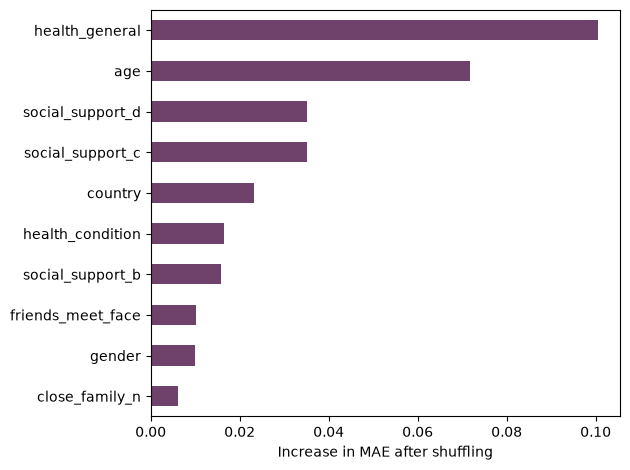

In [6]:
subset = test.sample(n=min(2000, len(test)), random_state=42)
importance = permutation_importance(
    saved["models"][selected], subset[saved["full"]], subset["ucla_total"],
    scoring="neg_mean_absolute_error", n_repeats=5, n_jobs=2, random_state=42,
)
importance_table = pd.DataFrame({"MAE increase": importance.importances_mean,
                                "SD across shuffles": importance.importances_std},
                                index=saved["full"]).sort_values("MAE increase", ascending=False)
importance_table.to_csv(tables / "permutation_importance.csv")
ax = importance_table.head(10)["MAE increase"].sort_values().plot.barh(color="#6e426a")
ax.set(xlabel="Increase in MAE after shuffling", ylabel="")
plt.tight_layout()
plt.savefig(figures / "05_predictive_importance.png", dpi=180)
plt.show()

## 7 Compare errors by age and municipality

Overall MAE can hide differences in how well the model predicts for different groups. We report groups with at least 30 test respondents because averages from very small groups can shift a lot with a few large errors.

In [7]:
groups = {
    "Age": pd.cut(test["age"], [15, 17, 29, 44, 59, np.inf],
                  labels=["16–17", "18–29", "30–44", "45–59", "60+"]),
    "Municipality": test["municipality_type_label"].where(test["municipality_type"].notna()),
}
group_errors = []
for variable, group in groups.items():
    summary = errors[[selected, "Median baseline"]].loc[:, lambda d: ~d.columns.duplicated()]
    summary = summary.groupby(group, observed=True).mean()
    summary["n"] = group.value_counts()
    group_errors.append(summary.loc[summary["n"] >= 30].assign(variable=variable))
subgroups = pd.concat(group_errors)
subgroups.to_csv(tables / "subgroup_test_errors.csv")
display(subgroups.round(3))

,Ridge,Median baseline,n,variable
16–17,1.252,1.594,32,Age
18–29,1.306,1.612,891,Age
30–44,1.258,1.531,1538,Age
45–59,1.234,1.594,1487,Age
60+,1.067,1.485,939,Age
A rural area or village,1.220,1.542,1180,Municipality
"Large town/ city (over 50,000 people)",1.236,1.570,2237,Municipality
"Small or medium-sized town (50,000 people or less)",1.203,1.545,1441,Municipality


## 8 Compare the two contact correlations

Both correlations come from the same respondents, so we resample their answers together. This gives us an interval for the difference between the correlations.

In [8]:
face = sample["friends_meet_face"].to_numpy()
remote = sample["friends_meet_tele"].to_numpy()
loneliness = sample["ucla_total"].to_numpy()
rho_difference = []
for _ in range(1000):
    draw = rng.integers(len(sample), size=len(sample))
    rho_difference.append(spearmanr(face[draw], loneliness[draw]).statistic
                          - spearmanr(remote[draw], loneliness[draw]).statistic)
comparison = pd.Series({
    "face_minus_remote": correlations["unweighted_rho"].iloc[0] - correlations["unweighted_rho"].iloc[1],
    "95% lower": np.quantile(rho_difference, .025),
    "95% upper": np.quantile(rho_difference, .975),
})
comparison.to_csv(tables / "paired_spearman_difference.csv")
display(comparison.round(3))

face_minus_remote   -0.034
95% lower           -0.045
95% upper           -0.023
dtype: float64

## 9 Summary

Ridge's test MAE was 1.223, compared with 1.556 for the median baseline. Test R² was 0.317. Weighted MAE was 1.230 for Ridge and 1.567 for the baseline.

Adding both friendship-contact measures to the full context set improved MAE by 0.0047 points (95% paired bootstrap interval 0.0018 to 0.0075). This is a very small gain. Adding remote contact when face-to-face contact was already present improved MAE by only 0.0001 points, with an interval spanning zero.

The model produced 89 predictions outside the 3–9 outcome range, and the diagnostic plot shows errors at the extremes. We report raw predictions consistently. Support and health help predict concurrent loneliness scores, but this does not identify causal relationships. The evaluation remains exploratory because the held-out sample was inspected during model development.
